Samajhna pehle: Day 69 mein ek Decision Tree ke liye GridSearchCV ka preview dekha tha. Aaj wahi cheez chaaron models (LogReg, Tree, Random Forest, XGBoost) par chalegi. Ek seekh yaad rakho: jitna zyada search karoge, utna best CV score optimistic hota jaata hai, kyunki 50 combinations mein se jo “lucky” nikla wahi jeeta. Isliye aaj ek nested CV bhi chalayenge, jo imandaar estimate deta hai.

Aaj ke rules:

1. Search sirf X_train_v2.csv par, CV se. Test set band hai.
2. Grid chhote rakho (data chhota hai). Result dekh kar grid ko baar-baar mat badlo. Agar best value grid ke kinare par aaye, to ek baar extend karo aur note karo.
3. Final model test dekhne se pehle likh kar commit karo (pre-registration). Day 85 mein test par sirf wahi ek baar score hoga.

1. src/models/search_spaces.py

In [3]:
"""Estimators + hyperparameter grids (Day 84). Grids chhote rakhe hain, data chhota hai."""
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import sys
import os
sys.path.append(os.path.abspath("../../"))
from src.features.build_features import NUM_V2


def get_search_spaces(pos_weight: float) -> dict:
    prep = ColumnTransformer([('s', StandardScaler(), NUM_V2)], remainder='passthrough')
    return {
        'LogReg': (
            Pipeline([('prep', prep), ('m', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
            {'m__C': [0.01, 0.1, 1, 10]},
        ),
        'Tree': (
            DecisionTreeClassifier(class_weight='balanced', random_state=42),
            {'max_depth': [3, 4, 5, 6], 'min_samples_leaf': [10, 30, 60]},
        ),
        'RandomForest': (
            RandomForestClassifier(class_weight='balanced_subsample', max_features='sqrt',
                                   n_jobs=1, random_state=42),
            {'n_estimators': [200, 400], 'max_depth': [4, 8, None], 'min_samples_leaf': [3, 10, 30]},
        ),
        'XGBoost': (
            XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
                          eval_metric='auc', tree_method='hist', n_jobs=1, random_state=42),
            {'n_estimators': [150, 300], 'learning_rate': [0.03, 0.1],
             'max_depth': [2, 3, 4], 'min_child_weight': [3, 10]},
        ),
    }

Models mein n_jobs=1 isliye hai ki parallelism GridSearchCV(n_jobs=-1) handle karega. Dono jagah parallel karne se CPU oversubscribe hota hai aur sab dheere chalta hai. Tree ko bhi ab v2 par dobara tune kar rahe hain, taaki us ko bhi barabar ka mauka mile (Day 83 ki shikayat).

2. Setup

In [5]:
import sys; sys.path.append('.')
import warnings; warnings.filterwarnings('ignore')
import time, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from src.models.search_spaces import get_search_spaces

X_tr = pd.read_csv('../../data/processed/X_train_v2.csv').astype(float)
y_tr = pd.read_csv('../../data/processed/y_train.csv').squeeze()
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

spaces = get_search_spaces(pos_weight)
n_combos = {k: int(np.prod([len(v) for v in g.values()])) for k, (_, g) in spaces.items()}
print(n_combos, "| fits (x5 folds):", {k: v * 5 for k, v in n_combos.items()})

{'LogReg': 4, 'Tree': 12, 'RandomForest': 18, 'XGBoost': 24} | fits (x5 folds): {'LogReg': 20, 'Tree': 60, 'RandomForest': 90, 'XGBoost': 120}


Total fits ka andaza pehle dekh lo. Agar tumhara laptop dheere hai, to RF aur XGBoost ke grids se ek-ek value hata do.

3. Grid search chalao (sab models, same folds, primary metric ROC-AUC):

In [7]:
search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # wahi folds jo Day 64B/70/83 mein the
scoring = {'auc': 'roc_auc', 'ap': 'average_precision'}

searches, rows = {}, []
for name, (est, grid) in spaces.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=search_cv, scoring=scoring, refit='auc',
                      n_jobs=-1, return_train_score=True)
    gs.fit(X_tr, y_tr)
    searches[name] = gs
    i = gs.best_index_
    rows.append({'model': name, 'best_cv_auc': gs.cv_results_['mean_test_auc'][i],
                 'auc_std': gs.cv_results_['std_test_auc'][i],
                 'best_cv_ap': gs.cv_results_['mean_test_ap'][i],
                 'train_auc': gs.cv_results_['mean_train_auc'][i], 'minutes': (time.time() - t0) / 60})
    print(f"{name}: {gs.best_params_}")

tuned_tbl = pd.DataFrame(rows).set_index('model')
print(tuned_tbl.round(3))

LogReg: {'m__C': 0.1}
Tree: {'max_depth': 4, 'min_samples_leaf': 30}
RandomForest: {'max_depth': 8, 'min_samples_leaf': 30, 'n_estimators': 400}
XGBoost: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 300}
              best_cv_auc  auc_std  best_cv_ap  train_auc  minutes
model                                                             
LogReg              0.796    0.012       0.821      0.801    0.003
Tree                0.785    0.014       0.797      0.808    0.008
RandomForest        0.799    0.015       0.819      0.847    0.538
XGBoost             0.802    0.016       0.823      0.833    0.198


refit='auc' ka matlab hai ki search ke baad best parameters se model poore X_tr par dobara fit hota hai (gs.best_estimator_). Primary metric ROC-AUC hai, kyunki hum customers ko risk ke hisaab se rank kar rahe hain, aur AUC threshold-free hai (Day 74).

4. Tuning ka gain, untuned se compare karo:

In [9]:
day83 = pd.read_csv('../../reports/cv_ensembles_day83.csv', index_col=0)
untuned = {'LogReg': 'LogReg v2', 'Tree': 'Tree v2 (Day 69 tuned)', 'RandomForest': 'RandomForest', 'XGBoost': 'XGBoost'}

cmp = pd.DataFrame({
    'untuned_cv_auc': {k: day83.loc[v, 'roc_auc'] for k, v in untuned.items()},
    'tuned_cv_auc': tuned_tbl['best_cv_auc'],
})
cmp['gain'] = cmp['tuned_cv_auc'] - cmp['untuned_cv_auc']
print(cmp.round(4))

              untuned_cv_auc  tuned_cv_auc    gain
LogReg                0.7960        0.7961  0.0001
Tree                  0.7789        0.7850  0.0061
RandomForest          0.7918        0.7988  0.0070
XGBoost               0.7962        0.8020  0.0058


Gain aam taur par chhota hota hai (0.00x). Aur ye gain poora asli nahi hai: tuned score us combination ka hai jo isi CV par sabse accha nikla, yaani isme chunav ki luck bhi shamil hai. Asli gain step 7 (nested CV) se dikhega.

5. Grid ke kinaare check karo (kya best value edge par hai?):

In [10]:
for name, gs in searches.items():
    grid = spaces[name][1]
    for p, vals in grid.items():
        best = gs.best_params_[p]
        vals_c = [v for v in vals if v is not None]
        if len(vals) > 1 and best in (vals_c[0], vals_c[-1]) and best is not None:
            print(f"{name}: {p}={best} grid ke kinare par hai, shayad grid ek baar extend karna padega")

RandomForest: n_estimators=400 grid ke kinare par hai, shayad grid ek baar extend karna padega
RandomForest: max_depth=8 grid ke kinare par hai, shayad grid ek baar extend karna padega
RandomForest: min_samples_leaf=30 grid ke kinare par hai, shayad grid ek baar extend karna padega
XGBoost: n_estimators=300 grid ke kinare par hai, shayad grid ek baar extend karna padega
XGBoost: learning_rate=0.03 grid ke kinare par hai, shayad grid ek baar extend karna padega
XGBoost: max_depth=2 grid ke kinare par hai, shayad grid ek baar extend karna padega
XGBoost: min_child_weight=3 grid ke kinare par hai, shayad grid ek baar extend karna padega


Agar koi warning aaye, to uss parameter ko ek baar extend karo (jaise max_depth mein ek aur value) aur search dobara chalao. Baar-baar extend mat karte jaana, warna tum test ki tarah CV ko bhi “yaad” kar loge.

6. Plateau dekho (kya best combination akela hai, ya bahut saare barabar hain?):

In [11]:
def top_results(gs, k=8):
    r = pd.DataFrame(gs.cv_results_)
    r = r.sort_values('rank_test_auc')[['params', 'mean_test_auc', 'std_test_auc', 'mean_train_auc', 'mean_fit_time']]
    r['gap'] = r['mean_train_auc'] - r['mean_test_auc']
    return r.head(k).round(3)

for name in ['RandomForest', 'XGBoost']:
    print(f"\n=== {name} ===")
    print(top_results(searches[name]).to_string())


=== RandomForest ===
                                                              params  mean_test_auc  std_test_auc  mean_train_auc  mean_fit_time    gap
11     {'max_depth': 8, 'min_samples_leaf': 30, 'n_estimators': 400}          0.799         0.015           0.847          4.437  0.048
17  {'max_depth': None, 'min_samples_leaf': 30, 'n_estimators': 400}          0.799         0.016           0.850          3.600  0.051
3      {'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 400}          0.798         0.016           0.821          4.047  0.023
16  {'max_depth': None, 'min_samples_leaf': 30, 'n_estimators': 200}          0.798         0.015           0.850          2.143  0.052
2      {'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 200}          0.798         0.016           0.821          1.755  0.023
10     {'max_depth': 8, 'min_samples_leaf': 30, 'n_estimators': 200}          0.798         0.015           0.846          2.307  0.048
1       {'max_depth': 4, '

Kaise padho: Agar top 8 rows ke mean_test_auc ek-doosre ke std_test_auc ke andar hain, to wo sab barabar achhe hain. Tab “rank 1” sirf luck hai, aur sabse simple aur sabse tez wala chuna jaata hai (1-standard-error rule, Day 69).

In [12]:
def pick_one_se(gs):
    r = pd.DataFrame(gs.cv_results_)
    best = r.loc[gs.best_index_]
    ok = r[r['mean_test_auc'] >= best['mean_test_auc'] - best['std_test_auc']]
    return ok.sort_values('mean_fit_time').iloc[0]['params']      # fit time simplicity ka proxy

for name, gs in searches.items():
    print(name, "| rank-1:", gs.best_params_, "\n      | 1-SE simple:", pick_one_se(gs))

LogReg | rank-1: {'m__C': 0.1} 
      | 1-SE simple: {'m__C': 0.01}
Tree | rank-1: {'max_depth': 4, 'min_samples_leaf': 30} 
      | 1-SE simple: {'max_depth': 3, 'min_samples_leaf': 10}
RandomForest | rank-1: {'max_depth': 8, 'min_samples_leaf': 30, 'n_estimators': 400} 
      | 1-SE simple: {'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 200}
XGBoost | rank-1: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 300} 
      | 1-SE simple: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 150}


mean_fit_time ko complexity ka proxy maana hai (kam trees, kam depth = tez). Agar 1-SE wala aur rank-1 wala alag hain, to 1-SE wala chuno, kyunki wahi naye data par zyada stable hota hai.

XGBoost ka ek plateau chart:

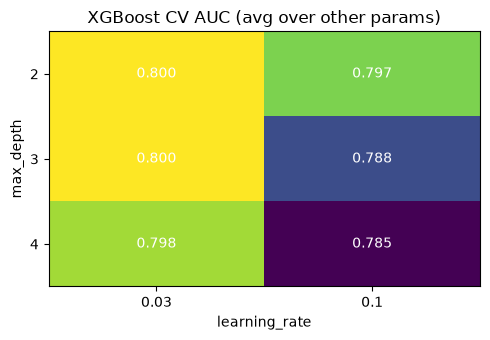

In [13]:
r = pd.DataFrame(searches['XGBoost'].cv_results_)
r['lr'] = r['param_learning_rate'].astype(float)
r['depth'] = r['param_max_depth'].astype(int)
pv = r.pivot_table(index='depth', columns='lr', values='mean_test_auc', aggfunc='mean')

plt.figure(figsize=(5, 3.5))
plt.imshow(pv.values, cmap='viridis', aspect='auto')
plt.xticks(range(len(pv.columns)), pv.columns)
plt.yticks(range(len(pv.index)), pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        plt.text(j, i, f"{pv.values[i, j]:.3f}", ha='center', va='center', color='white')
plt.xlabel('learning_rate'); plt.ylabel('max_depth')
plt.title('XGBoost CV AUC (avg over other params)')
plt.tight_layout()
plt.show()

Agar saare cells lagbhag ek jaise hain, to is data mein XGBoost hyperparameters par zyada sensitive nahi hai. Yeh achhi khabar hai, iska matlab model robust hai.

7. Nested CV: imandaar estimate (sabse zaroori step):

Normal GridSearchCV mein ek hi CV do kaam karta hai: parameter chunna aur score batana. Isse score optimistic hota hai. Nested CV mein outer folds sirf score ke liye hain, aur andar ki alag CV parameter chunti hai. Outer validation fold search ko kabhi dikhta hi nahi.

In [14]:
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=2024)   # n_repeats=2 karoge to behtar, par 2x slow
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)

nested = {}
for name, (est, grid) in spaces.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=inner, scoring='roc_auc', n_jobs=-1)
    nested[name] = cross_val_score(gs, X_tr, y_tr, cv=outer, scoring='roc_auc', n_jobs=1)
    print(f"{name}: nested AUC {nested[name].mean():.3f} +/- {nested[name].std():.3f}  ({(time.time() - t0) / 60:.1f} min)")

nested_df = pd.DataFrame(nested)

LogReg: nested AUC 0.796 +/- 0.012  (0.0 min)
Tree: nested AUC 0.778 +/- 0.014  (0.0 min)
RandomForest: nested AUC 0.802 +/- 0.013  (1.2 min)
XGBoost: nested AUC 0.803 +/- 0.014  (0.5 min)


Ek caveat: Yeh sabse dheema step hai. Agar bahut slow ho, to n_estimators ke options kam kar do (jaise sirf [200]) sirf nested ke liye.

Comparison table:

              search_best_auc (optimistic)  nested_auc (honest)  nested_std  \
LogReg                              0.7961               0.7963      0.0140   
Tree                                0.7850               0.7775      0.0161   
RandomForest                        0.7988               0.8022      0.0143   
XGBoost                             0.8020               0.8028      0.0158   

              optimism  
LogReg         -0.0002  
Tree            0.0075  
RandomForest   -0.0034  
XGBoost        -0.0008  


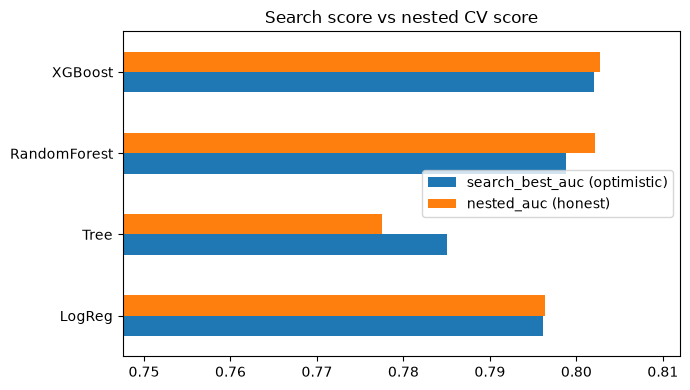

In [16]:
honest = pd.DataFrame({
    'search_best_auc (optimistic)': tuned_tbl['best_cv_auc'],
    'nested_auc (honest)': nested_df.mean(),
    'nested_std': nested_df.std(),
})
honest['optimism'] = honest['search_best_auc (optimistic)'] - honest['nested_auc (honest)']
print(honest.round(4))

ax = honest[['search_best_auc (optimistic)', 'nested_auc (honest)']].plot.barh(figsize=(7, 4))
ax.set_xlim(honest['nested_auc (honest)'].min() - 0.03, honest['search_best_auc (optimistic)'].max() + 0.01)
ax.set_title('Search score vs nested CV score')
plt.tight_layout()
plt.savefig('../../reports/tuning_optimism_day84.png', dpi=150)
plt.show()

optimism wo hissa hai jo chunav ki luck se aaya. Aam taur par bada model (XGBoost, jisme zyada hyperparameters hain) zyada optimistic hota hai, aur LogReg (sirf C) kam.

Fold-by-fold (outer folds same hain, to seedha compare ho sakta hai):

In [17]:
print(nested_df.round(3))
best_name = nested_df.mean().idxmax()
for name in nested_df.columns:
    if name != best_name:
        d = nested_df[best_name] - nested_df[name]
        print(f"{best_name} vs {name}: wins {int((d > 0).sum())}/{len(d)} | mean diff {d.mean():.4f} | std {d.std():.4f}")

   LogReg   Tree  RandomForest  XGBoost
0   0.820  0.805         0.826    0.830
1   0.789  0.769         0.794    0.792
2   0.796  0.777         0.804    0.803
3   0.783  0.763         0.791    0.794
4   0.794  0.775         0.795    0.795
XGBoost vs LogReg: wins 5/5 | mean diff 0.0064 | std 0.0048
XGBoost vs Tree: wins 5/5 | mean diff 0.0253 | std 0.0045
XGBoost vs RandomForest: wins 2/5 | mean diff 0.0006 | std 0.0028


8. Final model choose karo, aur test dekhne se PEHLE likh kar commit karo (pre-registration):

Chunne ka rule yeh rakho:

1. Nested AUC sabse zyada wala model candidate hai.
2. Agar doosre model ka nested AUC us se std ke andar hai, to simple/tez/samajhne mein aasan wala chuno (LogReg > Tree > RF > XGBoost).
3. Parameters mein 1-SE wala simple combination.

In [19]:
final_name = 'XGBoost'       # <- apna faisla likho, step 7 ki table dekh kar
final_params = pick_one_se(searches[final_name])      # ya searches[final_name].best_params_, apni pasand ka
print(final_name, final_params)

with open('../../reports/final_model_choice_day84.md', 'w') as f:
    f.write(f"""# Pre-registered final model (Day 84)
Decided on CV only. Test set NOT used for any decision (it will be scored once, on Day 85).

- Model: {final_name}
- Params: {json.dumps({k: (None if v is None else (v.item() if hasattr(v, 'item') else v)) for k, v in final_params.items()})}
- Nested CV AUC: {nested_df[final_name].mean():.4f} +/- {nested_df[final_name].std():.4f}
- Reason: [apni 2-3 line ki wajah likho: score, simplicity, stability]
- Metric for threshold later: chosen from CV out-of-fold predictions, not from test.
""")
print(open('../../reports/final_model_choice_day84.md').read())

XGBoost {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 150}
# Pre-registered final model (Day 84)
Decided on CV only. Test set NOT used for any decision (it will be scored once, on Day 85).

- Model: XGBoost
- Params: {"learning_rate": 0.03, "max_depth": 2, "min_child_weight": 3, "n_estimators": 150}
- Nested CV AUC: 0.8028 +/- 0.0158
- Reason: [apni 2-3 line ki wajah likho: score, simplicity, stability]
- Metric for threshold later: chosen from CV out-of-fold predictions, not from test.



Yeh file abhi commit karo (neeche command hai), test dekhne se pehle. Git ka timestamp saboot hai ki tumne test dekh kar model nahi chuna. Interview mein yeh bahut strong baat hai.

9. Tuned models save karo (Day 85 ke comparison ke liye):

In [21]:
import os
os.makedirs('models', exist_ok=True)
for name, gs in searches.items():
    joblib.dump(gs.best_estimator_, f"models/tuned_{name.lower()}_v2.joblib")

best_params = {n: {k: (v.item() if hasattr(v, 'item') else v) for k, v in gs.best_params_.items()}
               for n, gs in searches.items()}
with open('../../reports/best_params_day84.json', 'w') as f:
    json.dump(best_params, f, indent=2, default=str)

tuned_tbl.round(4).to_csv('../../reports/tuning_results_day84.csv')
honest.round(4).to_csv('../../reports/nested_cv_day84.csv')

Models .gitignore mein hain, to push nahi honge, aur wo theek hai. Parameters JSON mein rehte hain, jisse model dobara train ho sakta hai.

10. Ek imandaar baat: Ho sakta hai nested CV dikhaye ki tuning ka asli faida bahut chhota (ya shunya) tha, aur LogReg, RF, XGBoost sab ek ke aas-paas hain. Yeh achhi finding hai, kharab nahi. README mein likho, aur agar sab barabar hain to simplest model chuno. Chhote tabular data par yeh aam hai.

README ke liye note:

## Hyperparameter Tuning
Grid search (5-fold CV, ROC-AUC) on LogReg, Decision Tree, Random Forest, XGBoost.
Search scores are optimistic by construction, so I report a nested-CV estimate: [X] (honest) vs [X] (search best).
Final model chosen on CV only and committed before touching the test set (`reports/final_model_choice_day84.md`).

practice questions:

1. RandomizedSearchCV(n_iter=15) ko XGBoost ke bade grid (jaise 100+ combinations) par chalao aur GridSearch se score aur time compare karo. Kab randomized search behtar hai?
2. scoring='average_precision' ya 'f1' se XGBoost ki search dobara chalao. Best parameters badalte hain? Apne shabdon mein likho ki primary metric ka chunav tuning ka natija kaise badalta hai (Day 69 wala sawal).
3. Apne shabdon mein likho: “nested CV” aur “test set” mein kya fark hai, aur dono ki zaroorat kyun hai?